# Case study: plantiSMASH 2.0 BGC predictions vs PlantMetWiki genes and pathways

**Question.** All plantiSMASH BGCs are *predictions*. How many of them, across all genomes in the plantiSMASH 2.0 database, can be linked to PlantMetWiki genes and pathways?
How much do they overlap with the pathways they link to? And which evidence must a link carry so that users can judge it?

**Starting point.** PlantMetWiki already links BGCs to pathways for *Arabidopsis thaliana* only
([map-to-rdf](https://doi.org/10.5281/zenodo.20640349): 181 plantiSMASH links, 33 BGCs, 50 genes, 109 pathways).
That link works because BGC genes and PlantCyc genes share the same TAIR locus IDs.
For other species, plantiSMASH uses NCBI RefSeq gene models, which PlantCyc does not use.

**Approach.** Each BGC gene is linked to PlantMetWiki pathways in three tiers:

| Tier | Rule | Species |
|---|---|---|
| `gene_direct` | the BGC gene's TAIR locus is a gene of the pathway (= the existing PlantMetWiki links) | *A. thaliana* |
| `gene_uniprot` | the BGC's *biosynthetic* protein (RefSeq → UniProt) is an enzyme of the pathway | all |
| `gene_ec` | the biosynthetic protein's complete EC number (UniProt) catalyses a reaction of the pathway | all |

For every BGC we also record the evidence points from the main README:
- the prediction itself
- the detection rule(s)
- the plantiSMASH version
- the MIBiG match (KnownClusterBLAST, % of genes similar)
- the overlap with the pathway's nodes

All logic is in [`match_plantismash.py`](match_plantismash.py), which reuses the PlantMetWiki snapshots of the two earlier pilots. Numbers in the text are computed in the cells.

## How to reproduce

```bash
cd pilots/plantismash_overlap
uv venv --python 3.12 .venv
uv pip install --python .venv/bin/python -r requirements.txt   # pinned versions
.venv/bin/python match_plantismash.py      # first run: downloads plantiSMASH (~15 min) and maps proteins to UniProt
```

Then open this notebook with the `.venv` kernel and **Run All**.

| Input | How it is obtained | Frozen? |
|---|---|---|
| plantiSMASH 2.0 precalculated database, `geneclusters.js` of every genome | downloaded from `plantismash.bioinformatics.nl/precalc/v2/`, compact copy in `data/plantismash_v2/` | cache (gitignored); the database has no versioned download |
| RefSeq protein → UniProt accession + EC | UniProt ID-mapping service, saved as `data/refseq_to_uniprot.tsv.gz` | yes: snapshot 2026-09-29 |
| PlantMetWiki TAIR gene → pathway | SPARQL, `data/plantmetwiki_tair_gene_pathways.csv` | yes: snapshot 2026-09-29 |
| PlantMetWiki pathway ECs, enzyme UniProt ids, pathway classes | reused from `../meantools_overlap/data/` and `../metabolomics_overlap/data/` | yes |

**Reproducibility caveat.** The plantiSMASH website serves the current database, with no version or checksum.
The compiled cluster table [`results/plantismash_clusters.csv.gz`](results/plantismash_clusters.csv.gz) is therefore committed as the record of what was analysed.

## 1. Setup and provenance

In [1]:
import platform, re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import match_plantismash as mp

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 200)

def say(text):
    display(Markdown(text))

res = mp.build()
clusters, genes, links, bp = res["clusters"], res["genes"], res["links"], res["bgc_pathways"]
uniprot_map, pmw_genes, tair_pw = res["uniprot_map"], res["pmw_genes"], res["tair_pw"]
TIERS = list(mp.GENE_TIERS)

In [2]:
cache = sorted(mp.CACHE.glob("*.json.gz"))
display(pd.Series({"python": platform.python_version(), "pandas": pd.__version__,
                   "plantiSMASH genomes cached": len(cache),
                   "cache last modified": pd.Timestamp(max(p.stat().st_mtime for p in cache), unit="s").strftime("%Y-%m-%d %H:%M")},
                  name="value").to_frame())

,value
python,3.12.9
pandas,3.0.6
plantiSMASH genomes cached,430
cache last modified,2026-09-29 14:37


## 2. The plantiSMASH 2.0 database

The index lists 431 entries; one (`tfbs-finder`) is a tool folder, not a genome, and is skipped, which leaves 430 genomes.

In [3]:
rules = clusters.explode("rules")
n_mibig = clusters["mibig_id"].notna().sum()
say(f"""- **{len(clusters):,}** predicted BGCs in **{clusters['genome'].nunique()}** genomes
  ({clusters['species'].nunique()} species, {clusters['genus'].nunique()} genera), with **{len(genes):,}** gene entries,
  {genes['biosynthetic'].sum():,} of them marked *biosynthetic*.
- **{(clusters['rules'].str.len() > 1).sum():,}** BGCs ({100 * (clusters['rules'].str.len() > 1).mean():.0f}%) are hybrids, i.e. detected by more than one rule.
- **{n_mibig:,}** BGCs ({100 * n_mibig / len(clusters):.1f}%) have a KnownClusterBLAST hit to MIBiG;
  **{(clusters['mibig_similarity'] == 100).sum()}** with 100% of the MIBiG genes similar.""")
rules["rules"].value_counts().to_frame("BGCs per detection rule (hybrids counted per rule)")

- **30,426** predicted BGCs in **430** genomes
  (430 species, 270 genera), with **619,442** gene entries,
  161,054 of them marked *biosynthetic*.
- **5,162** BGCs (17%) are hybrids, i.e. detected by more than one rule.
- **1,682** BGCs (5.5%) have a KnownClusterBLAST hit to MIBiG;
  **136** with 100% of the MIBiG genes similar.

,BGCs per detection rule (hybrids counted per rule)
rules,
saccharide,12140
cyclopeptide,4454
alkaloid,4161
terpene,3775
fatty_acid,3143
putative,3036
polyketide,2262
lignan,1415
transporter_associated,1402


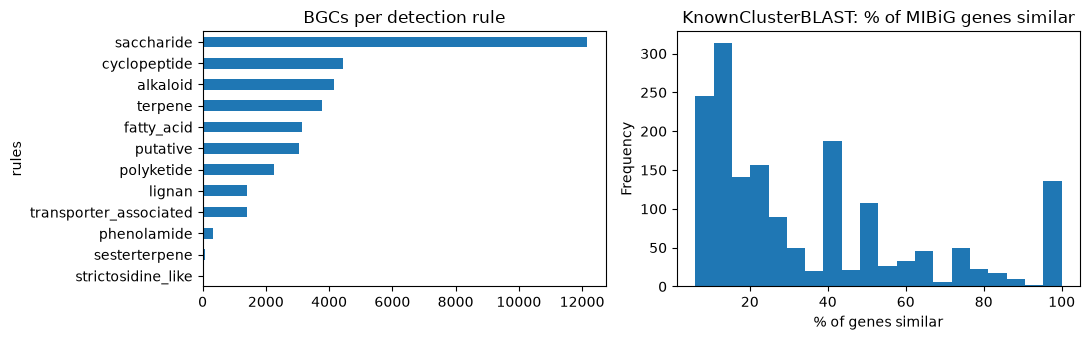

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
rules["rules"].value_counts().plot.barh(ax=axes[0]); axes[0].invert_yaxis(); axes[0].set_title("BGCs per detection rule")
clusters["mibig_similarity"].dropna().plot.hist(bins=20, ax=axes[1]); axes[1].set_title("KnownClusterBLAST: % of MIBiG genes similar")
axes[1].set_xlabel("% of genes similar"); plt.tight_layout()

**Comments**
- **The detection rules are the first evidence point, and they are *types* of prediction.** plantiSMASH 2.0 has 12 rules (terpene, saccharide, alkaloid, …). Each requires specific core enzyme domains (pHMMs) co-located in the genome.
- **"putative" is not one of the 12 rules.** It marks loci that plantiSMASH flags without a full rule match.
- **Most BGCs have no MIBiG counterpart**, as expected for predictions. A MIBiG match with 100% of the genes similar is the strongest support a prediction can get without experiments.

## 3. *A. thaliana*: reproducing PlantMetWiki's existing BGC–pathway links

The `gene_direct` tier uses the same rule as the PlantMetWiki query in `map-to-rdf`: a BGC gene's TAIR IRI is a `wp:GeneProduct` of a PlantMetWiki pathway.

In [5]:
ath = bp[bp["species"] == "Arabidopsis thaliana"]
direct = links[(links["tier"] == "gene_direct")]
say(f"""**Findings**
- Direct links: **{ath.loc[ath['tiers'].str.contains('gene_direct'), 'bgc'].nunique()}** BGCs,
  **{direct['locus_tag'].nunique()}** genes and **{direct['plantcyc_id'].nunique()}** pathways
  (map-to-rdf reported 33 BGCs, 50 genes, 109 pathways).
- We find **more** genes and pathways than the Zenodo summary, which was built on an earlier PlantMetWiki release (`r17.0.0_20260203162556`).
  Compared offline, **all 181** gene–pathway pairs of the plantiSMASH links in that summary are among our {direct[['locus_tag', 'plantcyc_id']].drop_duplicates().shape[0]} pairs, and none is missing.
  The extra pairs probably come from the newer release now served by the endpoint (not verified).
- Single-reaction diagrams (`…-RXN`), which PlantMetWiki also types as `wp:Pathway`, are excluded here.""")

**Findings**
- Direct links: **33** BGCs,
  **53** genes and **216** pathways
  (map-to-rdf reported 33 BGCs, 50 genes, 109 pathways).
- We find **more** genes and pathways than the Zenodo summary, which was built on an earlier PlantMetWiki release (`r17.0.0_20260203162556`).
  Compared offline, **all 181** gene–pathway pairs of the plantiSMASH links in that summary are among our 383 pairs, and none is missing.
  The extra pairs probably come from the newer release now served by the endpoint (not verified).
- Single-reaction diagrams (`…-RXN`), which PlantMetWiki also types as `wp:Pathway`, are excluded here.

## 4. Extending to all species: UniProt and EC tiers

How many BGCs link to at least one PlantMetWiki pathway, per tier?

In [6]:
bio = genes[genes["biosynthetic"]]
mapped = bio["protein_id"].isin(uniprot_map["protein_id"])
with_ec = bio["protein_id"].isin(mp.protein_ec(uniprot_map)["protein_id"])
partial = uniprot_map["ec"].fillna("").str.contains(r"-")
say(f"""**Protein → UniProt → EC**
- {len(bio):,} biosynthetic gene entries; **{100 * mapped.mean():.0f}%** map to a UniProt entry and
  **{100 * with_ec.mean():.0f}%** to a *complete* EC number.
- **{partial.sum():,}** mapped UniProt entries carry only a *partial* EC (e.g. `2.4.1.-`, `1.14.-.-`).
  Partial ECs are typical for P450s and glycosyltransferases, the hallmark BGC enzymes, and can't be matched to a specific reaction.""")
tier_cov = pd.DataFrame({t: [links.loc[links["tier"] == t, "bgc"].nunique(), links.loc[links["tier"] == t, "species"].nunique(),
                             links.loc[links["tier"] == t, "plantcyc_id"].nunique()] for t in TIERS},
                        index=["BGCs linked", "species", "PlantMetWiki pathways"]).T
tier_cov["% of all BGCs"] = (100 * tier_cov["BGCs linked"] / len(clusters)).round(1)
tier_cov

**Protein → UniProt → EC**
- 161,054 biosynthetic gene entries; **49%** map to a UniProt entry and
  **6%** to a *complete* EC number.
- **10,227** mapped UniProt entries carry only a *partial* EC (e.g. `2.4.1.-`, `1.14.-.-`).
  Partial ECs are typical for P450s and glycosyltransferases, the hallmark BGC enzymes, and can't be matched to a specific reaction.

,BGCs linked,species,PlantMetWiki pathways,% of all BGCs
gene_direct,33,1,216,0.1
gene_uniprot,43,8,139,0.1
gene_ec,5237,238,538,17.2


In [7]:
per_species = (bp.groupby("species").agg(bgcs_linked=("bgc", "nunique"), pathways=("plantcyc_id", "nunique"))
               .join(clusters.groupby("species")["bgc"].nunique().rename("bgcs_total")))
per_species["% linked"] = (100 * per_species["bgcs_linked"] / per_species["bgcs_total"]).round(1)
per_species.sort_values("bgcs_linked", ascending=False).head(20)

,bgcs_linked,pathways,bgcs_total,% linked
species,,,,
Urochloa decumbens,151,103,407,37.1
Rhynchospora pubera,109,104,245,44.5
Triticum aestivum,94,127,302,31.1
Digitaria exilis,83,100,252,32.9
Helianthus anomalus,59,169,83,71.1
Linum tenue,58,124,189,30.7
Miscanthus lutarioriparius,55,108,157,35.0
Eragrostis curvula,53,97,154,34.4
Arabidopsis thaliana,53,300,65,81.5


**Interpretation**
- **Only the UniProt tier gives specific links outside Arabidopsis.** It links a BGC to a pathway when a BGC protein *is* a curated PlantCyc enzyme. PlantCyc enzymes come from many species, but only a few proteins per species are curated.
- **The EC tier reaches many BGCs, but the links are weak.** An EC number describes a reaction type, and core BGC enzymes often only have partial ECs.
- **Without the gene-ID bridge, the other species depend on these protein-level tiers.** An identifier crosswalk (BridgeDb: RefSeq/NCBI Gene ↔ Phytozome/ITAG) would add direct links for the species PlantCyc curates, e.g. tomato and rice.

## 5. How reliable is the EC tier? Validation in *A. thaliana*

In Arabidopsis we have both kinds of link, so the EC-tier BGC–pathway pairs can be compared with the direct pairs.
The direct links are not a perfect truth (they come from genes shared with a curated pathway), but they are the best reference available.

In [8]:
ath_ec = set(map(tuple, links[(links["species"] == "Arabidopsis thaliana") & (links["tier"] == "gene_ec")][["bgc", "plantcyc_id"]].drop_duplicates().values))
ath_direct = set(map(tuple, links[links["tier"] == "gene_direct"][["bgc", "plantcyc_id"]].drop_duplicates().values))
both = ath_ec & ath_direct
recall = len(both) / len(ath_direct) if ath_direct else float("nan")
precision = len(both) / len(ath_ec) if ath_ec else float("nan")
say(f"""**Findings**
- Direct BGC–pathway pairs: **{len(ath_direct)}**; EC-tier pairs: **{len(ath_ec)}**; found by both: **{len(both)}**.
- **Recall of the EC tier** (share of direct pairs it also finds): **{100 * recall:.0f}%**.
- **Agreement** (share of EC-tier pairs that are also direct): **{100 * precision:.0f}%**.""")

**Findings**
- Direct BGC–pathway pairs: **350**; EC-tier pairs: **256**; found by both: **77**.
- **Recall of the EC tier** (share of direct pairs it also finds): **22%**.
- **Agreement** (share of EC-tier pairs that are also direct): **30%**.

In [9]:
cat = bp[bp["species"] == "Arabidopsis thaliana"].assign(best=lambda d: d["best_tier"])
ct = pd.crosstab(cat["best"], cat["category"].fillna("unclassified"), normalize="index").mul(100).round(1).reindex(TIERS)
ct

category,hormones,primary,specialized (secondary),super-pathway / cluster,unclassified
best,,,,,
gene_direct,2.6,45.4,47.4,3.1,1.4
gene_uniprot,8.3,18.8,68.8,4.2,0.0
gene_ec,0.7,34.5,61.5,0.7,2.7


**Interpretation**
- **The EC tier is imprecise.** Most of its pairs have no direct support. A BGC enzyme with a common EC (a generic dehydrogenase or methyltransferase) matches many unrelated pathways.
- **It also misses most direct links**, because the linking gene often has no, or only a partial, EC.
- **It is not simply biased towards primary metabolism.** The table above shows the share of pathway categories per tier. Compare the `primary` column of `gene_ec` with `gene_direct` before drawing conclusions.
- **Consequence for the evidence model:** an EC-only link is a *weak, hypothesis-level* statement. It should always carry its tier and overlap score, and should not be shown as a PlantMetWiki fact.

In [10]:
say(f"Share of **primary** pathways among Arabidopsis BGC–pathway pairs: direct **{ct.loc['gene_direct', 'primary']}%**, "
    f"UniProt **{ct.loc['gene_uniprot', 'primary']}%**, EC **{ct.loc['gene_ec', 'primary']}%**; "
    f"specialized: **{ct.loc['gene_direct', 'specialized (secondary)']}%**, **{ct.loc['gene_uniprot', 'specialized (secondary)']}%**, **{ct.loc['gene_ec', 'specialized (secondary)']}%**.")

Share of **primary** pathways among Arabidopsis BGC–pathway pairs: direct **45.4%**, UniProt **18.8%**, EC **34.5%**; specialized: **47.4%**, **68.8%**, **61.5%**.

## 6. Overlap with pathway nodes and consistency with the detection rule

In [11]:
strong = bp[bp["best_tier"] != "gene_ec"].copy()
say(f"""- **{len(strong)}** BGC–pathway links from the direct or UniProt tier ({strong['bgc'].nunique()} BGCs, {strong['species'].nunique()} species);
  **{(bp['best_tier'] == 'gene_ec').sum():,}** EC-only links.
- Shared genes per strong link: median **{strong['n_bgc_genes'].median():.0f}**, max **{strong['n_bgc_genes'].max()}**.""")
cols = ["bgc", "type", "pathway", "category", "best_tier", "n_bgc_genes", "linking_nodes", "mibig_name", "mibig_similarity"]
strong.sort_values(["n_bgc_genes", "mibig_similarity"], ascending=False)[cols].head(30)

- **448** BGC–pathway links from the direct or UniProt tier (57 BGCs, 8 species);
  **24,110** EC-only links.
- Shared genes per strong link: median **1**, max **5**.

,bgc,type,pathway,category,best_tier,n_bgc_genes,linking_nodes,mibig_name,mibig_similarity
2444,Arabidopsis_thaliana_GCF_000001735.4/#cluster-50,lignan-alkaloid,ubiquinol-9 biosynthesis (late decarboxylation),primary,gene_uniprot,5,"EC 2.5.1.39, Q93YP7",NaN,NaN
2535,Arabidopsis_thaliana_GCF_000001735.4/#cluster-60,terpene,heme degradation I,primary,gene_direct,3,"AT5G47990, AT5G48000, AT5G48010",thalianol/thaliandiol/thalianin,100.0
2536,Arabidopsis_thaliana_GCF_000001735.4/#cluster-60,terpene,thalianol and derivatives biosynthesis,specialized (secondary),gene_direct,3,"AT5G47990, AT5G48000, AT5G48010, EC 5.4.99.31",thalianol/thaliandiol/thalianin,100.0
2213,Arabidopsis_thaliana_GCF_000001735.4/#cluster-24,saccharide,quercetin glycoside biosynthesis (Arabidopsis),specialized (secondary),gene_direct,3,"AT2G29730, AT2G29740, AT2G29750, EC 2.4.1.237, EC 2.4.1.91",NaN,NaN
2215,Arabidopsis_thaliana_GCF_000001735.4/#cluster-24,saccharide,rutin biosynthesis,specialized (secondary),gene_direct,3,"AT2G29730, AT2G29740, EC 2.4.1.91",NaN,NaN
2217,Arabidopsis_thaliana_GCF_000001735.4/#cluster-24,saccharide,hypusine biosynthesis,primary,gene_direct,3,"AT2G29730, AT2G29740, AT2G29750",NaN,NaN
2220,Arabidopsis_thaliana_GCF_000001735.4/#cluster-24,saccharide,superpathway of flavones and derivatives biosynthesis,super-pathway / cluster,gene_direct,3,"AT2G29730, AT2G29740, AT2G29750, EC 2.4.1.237, EC 2.4.1.91",NaN,NaN
2221,Arabidopsis_thaliana_GCF_000001735.4/#cluster-24,saccharide,superpathway of flavones and derivatives biosynthesis,super-pathway / cluster,gene_direct,3,"AT2G29730, AT2G29740, AT2G29750, EC 2.4.1.237, EC 2.4.1.91",NaN,NaN
2222,Arabidopsis_thaliana_GCF_000001735.4/#cluster-24,saccharide,flavonol glucosylation I,specialized (secondary),gene_direct,3,"AT2G29730, AT2G29740, EC 2.4.1.91",NaN,NaN
2225,Arabidopsis_thaliana_GCF_000001735.4/#cluster-24,saccharide,daphnetin modification,specialized (secondary),gene_direct,3,"AT2G29730, AT2G29740, AT2G29750, EC 2.4.1.91",NaN,NaN


In [12]:
# Does the detection rule fit the pathway class? Compare terpene-rule BGCs vs others on strong links
strong["terpene_rule"] = strong["type"].str.contains("terpene")
pd.crosstab(strong["terpene_rule"], strong["category"].fillna("unclassified"))

category,hormones,primary,specialized (secondary),super-pathway / cluster,unclassified
terpene_rule,,,,,
False,7,112,125,7,4
True,10,60,114,8,1


**Comments**
- **A shared-gene count does not make a link correct.** Several of the links with the most shared genes point to pathways that do not fit the BGC chemistry. Examples: the thalianol cluster (`cluster-60`) also links to *heme degradation I* through the same three genes, and a saccharide cluster (`cluster-24`) to *hypusine biosynthesis*. I have not investigated why these genes sit in those pathways, but these links should be checked before they are shown as facts.
- **`n_bgc_genes` is a simple overlap score:** how many BGC genes are nodes of the pathway. With `pathway_n_tair_genes` and `pathway_n_ecs` it can be turned into a fraction (the "X overlap" evidence point). The evidence node should also record *which* genes link the BGC, so users can inspect each link.

In [13]:
cats = strong["category"].fillna("unclassified").value_counts(normalize=True).mul(100).round(0)
say("Pathway categories of the strong links: " + ", ".join(f"{k} **{int(v)}%**" for k, v in cats.items()) + ".")

Pathway categories of the strong links: specialized (secondary) **53%**, primary **38%**, hormones **4%**, super-pathway / cluster **3%**, unclassified **1%**.

## 7. MIBiG matches vs PlantMetWiki links

In [14]:
mb = clusters[clusters["mibig_id"].notna()].copy()
mb["linked_strong"] = mb["bgc"].isin(strong["bgc"])
mb["match"] = np.where(mb["mibig_similarity"] == 100, "complete (100%)", "partial (<100%)")
display(pd.crosstab(mb["match"], mb["linked_strong"], margins=True).rename(columns={True: "strong PlantMetWiki link", False: "no strong link"}))
mb[mb["linked_strong"]].merge(strong[["bgc", "pathway"]], on="bgc")[["bgc", "mibig_id", "mibig_name", "mibig_similarity", "pathway"]].drop_duplicates().head(20)

linked_strong,no strong link,strong PlantMetWiki link,All
match,,,
complete (100%),132,4,136
partial (<100%),1534,12,1546
All,1666,16,1682


,bgc,mibig_id,mibig_name,mibig_similarity,pathway
0,Arabidopsis_thaliana_GCF_000001735.4/#cluster-16,BGC0001314,tirucalla,21.0,sucrose degradation II (sucrose synthase)
1,Arabidopsis_thaliana_GCF_000001735.4/#cluster-16,BGC0001314,tirucalla,21.0,scopoletin biosynthesis
2,Arabidopsis_thaliana_GCF_000001735.4/#cluster-16,BGC0001314,tirucalla,21.0,salidroside biosynthesis
3,Arabidopsis_thaliana_GCF_000001735.4/#cluster-16,BGC0001314,tirucalla,21.0,methyl ketone biosynthesis (engineered)
4,Arabidopsis_thaliana_GCF_000001735.4/#cluster-16,BGC0001314,tirucalla,21.0,superpathway of anaerobic sucrose degradation
5,Arabidopsis_thaliana_GCF_000001735.4/#cluster-16,BGC0001314,tirucalla,21.0,UDP-glucose biosynthesis (from sucrose)
6,Arabidopsis_thaliana_GCF_000001735.4/#cluster-17,BGC0000670,thalianol/thaliandiol/thalianin,66.0,superpathway of isoleucine and valine biosynthesis
7,Arabidopsis_thaliana_GCF_000001735.4/#cluster-17,BGC0000670,thalianol/thaliandiol/thalianin,66.0,gibberellin inactivation I (2β-hydroxylation)
8,Arabidopsis_thaliana_GCF_000001735.4/#cluster-17,BGC0000670,thalianol/thaliandiol/thalianin,66.0,lupeol biosynthesis
9,Arabidopsis_thaliana_GCF_000001735.4/#cluster-17,BGC0000670,thalianol/thaliandiol/thalianin,66.0,folate polyglutamylation II


**Interpretation**
- **Two independent pieces of evidence can support a prediction:** a MIBiG match (the BGC resembles an experimentally characterized cluster) and a PlantMetWiki link (its genes are curated pathway enzymes).
- **When both agree**, e.g. a thalianol-like BGC linked to *thalianol biosynthesis*, the prediction is well supported.
- **Most complete MIBiG matches have no strong link** (see the table). Mostly this reflects the missing gene-ID bridge for species other than *A. thaliana*, not a gap in PlantMetWiki. An identifier crosswalk is needed before such a BGC can be called a curation gap.

## 8. An evidence model for plantiSMASH BGCs and BGC–pathway links

The five statements from the README, with the terms used in [`results/bgc_evidence.ttl`](results/bgc_evidence.ttl). All terms were checked in the EBI Ontology Lookup Service.

| Statement | Modelled as | Terms | Status |
|---|---|---|---|
| there is a BGC | the cluster node | `SO:0002357` biosynthetic_gene_cluster; genes via **`BFO:0000051` has part** | exists |
| … it is a *prediction* | evidence node | `ECO:0000256` match to sequence model evidence used in automatic assertion (pHMM rule hits) + `ECO:0007327` genomic context evidence used in automatic assertion (co-location) | exists |
| detected by rule X | on the evidence node | `lodp:detectionRule "terpene"`, `lodp:coreDomain "…"` | **gap:** no vocabulary for plantiSMASH rules; the 12 rule names could become a small SKOS scheme |
| from plantiSMASH version X | provenance | `prov:wasGeneratedBy` → activity with `SWO:0004000` has version | exists (but the precalc database states no exact version) |
| complete / partial match with MIBiG | mapping + evidence | `skos:exactMatch` (100%) / `skos:closeMatch` (<100%) → MIBiG IRI; `ECO:0000249` sequence similarity evidence used in automatic assertion, with `% genes similar` | exists (the threshold is a choice) |
| X overlap with pathway nodes | a BGC–pathway link node | `RO:0002131` overlaps (BGC, pathway); `ECO:0007679` combinatorial computational evidence used in automatic assertion; link tier, shared genes, shared ECs, fraction of pathway ECs | **gap:** overlap scores need defined properties |

**Two fixes for PlantMetWiki's current BGC graph**
1. **Fix the *has part* IRI.** It uses `obo:RO_0000051`, which I could not find in the Ontology Lookup Service. The OBO *has part* term is **`BFO:0000051`**. Worth checking with the `map-to-rdf` authors.
2. **Add the missing evidence.** The graph stores only BGC → gene, a label and the source. It has no rule, version, MIBiG match or evidence type, so users can't tell predictions apart from curated MIBiG clusters.

**Why a separate link node?** The BGC–pathway relation is itself a computed claim with its own evidence (tier and overlap).
Reifying it keeps the BGC's prediction evidence separate from the evidence of the link.

In [15]:
ttl = (mp.RESULTS / "bgc_evidence.ttl").read_text()
say(f"`results/bgc_evidence.ttl`: **{ttl.count('a obo:SO_0002357')}** BGCs and **{ttl.count('a lodp:BGCPathwayLink')}** BGC–pathway links "
    f"(direct and UniProt tiers only), {len(ttl) / 1e6:.1f} MB. Example BGC with a MIBiG match, and one link:")
i = ttl.index("skos:exactMatch"); start = ttl.rindex("\n\n", 0, i) + 2
print(ttl[start:ttl.index(" .\n", i) + 3])
j = ttl.index("a lodp:BGCPathwayLink"); start = ttl.rindex("\n\n", 0, j) + 2
print(ttl[start:ttl.index(" .\n", j) + 3])

`results/bgc_evidence.ttl`: **57** BGCs and **448** BGC–pathway links (direct and UniProt tiers only), 0.3 MB. Example BGC with a MIBiG match, and one link:

<https://plantismash.bioinformatics.nl/precalc/v2/Arabidopsis_thaliana_GCF_000001735.4/index.html#cluster-35> a obo:SO_0002357 ;   # biosynthetic_gene_cluster
    rdfs:label "Arabidopsis_thaliana_GCF_000001735.4/#cluster-35" ;
    sio:SIO_000772 [ a obo:ECO_0000256 , obo:ECO_0007327 ;
        prov:wasGeneratedBy lodp:plantismash_v2_database ;
        lodp:detectionRule "sesterterpene" ;
        lodp:coreDomain "Terpene_synth" , "Terpene_synth_C" , "polyprenyl_synt" ] ;
    skos:exactMatch <https://mibig.secondarymetabolites.org/repository/BGC0001756> ;
    lodp:mibigMatchEvidence [ a obo:ECO_0000249 ;   # sequence similarity (KnownClusterBLAST)
        lodp:percentGenesSimilar "100"^^xsd:integer ] .

lodp:link_Arabidopsis_thaliana_GCF_000001735_4__cluster_1_GLUTORN_PWY a lodp:BGCPathwayLink ;
    obo:RO_0002131 <https://plantismash.bioinformatics.nl/precalc/v2/Arabidopsis_thaliana_GCF_000001735.4/index.html#cluster-1> , pmw:PC581 ;   # overlaps
    lodp:anchoredInPathway pmw:PC581 ;
  

## 9. Summary

In [16]:
say(f"""
- **Database.** {len(clusters):,} predicted BGCs in {clusters['genome'].nunique()} genomes; {100 * n_mibig / len(clusters):.1f}% resemble a MIBiG cluster.
- **Direct links (A. thaliana)** include all of PlantMetWiki's existing BGC–pathway links, plus more from the newer release.
- **Other species.** Only the UniProt tier gives specific links ({tier_cov.loc['gene_uniprot', 'BGCs linked']} BGCs in {tier_cov.loc['gene_uniprot', 'species']} species).
  The EC tier links {tier_cov.loc['gene_ec', 'BGCs linked']:,} BGCs but agrees with direct links for only {100 * precision:.0f}% of its Arabidopsis pairs.
- **Evidence.** Rule, version, MIBiG similarity and overlap can all be expressed with existing terms (SO, ECO, SKOS, RO, PROV, SWO).
  Two gaps need small local vocabularies: plantiSMASH detection rules and overlap scores.
- **PlantMetWiki BGC graph.** It uses `RO_0000051` for *has part*, which I could not find in the Ontology Lookup Service (the OBO term is `BFO:0000051`); worth checking with the `map-to-rdf` authors. It also lacks the evidence fields.
""")


- **Database.** 30,426 predicted BGCs in 430 genomes; 5.5% resemble a MIBiG cluster.
- **Direct links (A. thaliana)** include all of PlantMetWiki's existing BGC–pathway links, plus more from the newer release.
- **Other species.** Only the UniProt tier gives specific links (43 BGCs in 8 species).
  The EC tier links 5,237 BGCs but agrees with direct links for only 30% of its Arabidopsis pairs.
- **Evidence.** Rule, version, MIBiG similarity and overlap can all be expressed with existing terms (SO, ECO, SKOS, RO, PROV, SWO).
  Two gaps need small local vocabularies: plantiSMASH detection rules and overlap scores.
- **PlantMetWiki BGC graph.** It uses `RO_0000051` for *has part*, which I could not find in the Ontology Lookup Service (the OBO term is `BFO:0000051`); worth checking with the `map-to-rdf` authors. It also lacks the evidence fields.


**Next steps**
- [ ] Identifier crosswalk (BridgeDb / NCBI Gene ↔ Phytozome) for tomato, rice and other PlantCyc species, to add direct links.
- [ ] Species-aware links: is the pathway recorded in PlantMetWiki for the BGC's species or genus?
- [ ] A SKOS scheme for the 12 plantiSMASH detection rules, and properties for overlap scores.
- [ ] Load `results/bgc_evidence.ttl` into a test graph next to PlantMetWiki and write example SPARQL queries (e.g. "predicted terpene BGCs with a complete MIBiG match and a curated pathway").
- [ ] Discuss the `RO_0000051` → `BFO:0000051` fix in `map-to-rdf`.